In [3]:
import numpy as np
from qiskit import ClassicalRegister, QuantumCircuit, QuantumRegister
from qiskit import transpile
import numpy as np
import math
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from qiskit_aer.noise import (NoiseModel, QuantumError, ReadoutError,
    pauli_error, depolarizing_error, thermal_relaxation_error)
#import bitstring
from qiskit_aer import AerSimulator
# import classes as c
import sys
sys.path.insert(0, "/home/dustinseboldt/Desktop/iqpe")
from HPC.Upload.pyfiles import classes as c

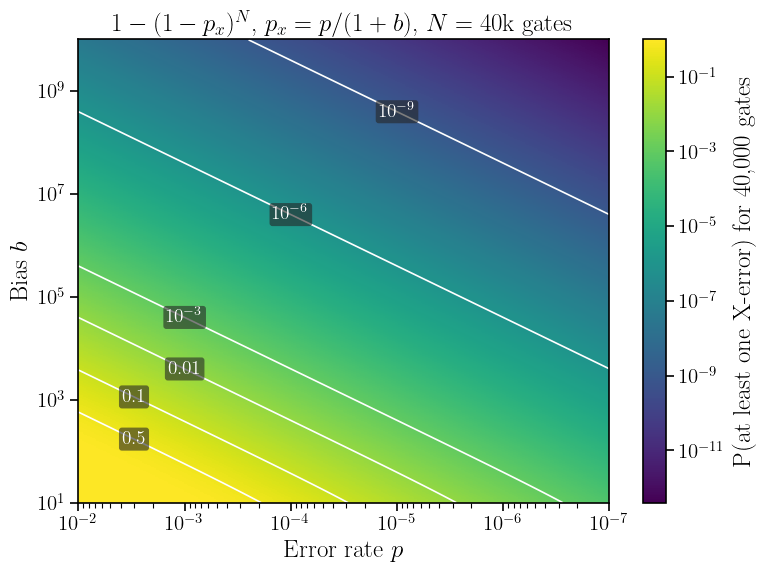

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

gates = 40_000

plt.rcParams.update({"font.family": "serif", "text.usetex": True,
                     "font.size": 16, "axes.labelsize": 18, "axes.titlesize": 18,
                     "legend.fontsize": 14, "xtick.labelsize": 15, "ytick.labelsize": 15,
                     "axes.linewidth": 1.2,
                     "xtick.major.width": 1.2, "ytick.major.width": 1.2,
                     "xtick.minor.width": 0.8, "ytick.minor.width": 0.8,
                     "xtick.major.size": 6, "ytick.major.size": 6,
                     "xtick.minor.size": 3.5, "ytick.minor.size": 3.5})

# Axes: error rate p (log, 1e-2 -> 1e-7) and bias b (log, 1e1 -> 1e10)
p = np.logspace(-2, -7, 400)
bias = np.logspace(1, 10, 400)
P, B = np.meshgrid(p, bias)
p_x = P / (1 + B)

# Probability of NO error:            (1 - p_x)**gates
# Probability of AT LEAST ONE error:  1 - (1 - p_x)**gates
# log1p/expm1 keep precision when p_x is tiny (down to ~1e-17)
p_no_err = np.exp(gates * np.log1p(-p_x))
p_err = -np.expm1(gates * np.log1p(-p_x))

fig, ax = plt.subplots(figsize=(8, 6))
mesh = ax.pcolormesh(P, B, p_err, shading="auto", cmap="viridis",
                     norm=LogNorm(vmin=p_err.min(), vmax=1), rasterized=True)
cbar = fig.colorbar(mesh, ax=ax)
cbar.set_label(f"P(at least one X-error) for {gates:,} gates")
cbar.ax.tick_params(labelsize=15, width=1.2, length=6)
cbar.outline.set_linewidth(1.2)

# Contour lines for a few reference probabilities
# (contour on log10 values so the lines are evenly resolved across decades)
levels = [1e-9, 1e-6, 1e-3, 1e-2, 0.1, 0.5]
cs = ax.contour(P, B, np.log10(p_err), levels=np.log10(levels),
                colors="white", linewidths=1.2, linestyles="solid")

def fmt(v):
    lvl = 10**v
    return f"${lvl:g}$" if lvl >= 0.01 else rf"$10^{{{round(v)}}}$"

# Place labels by hand so they don't pile up at the edges:
# for small values P_err ~ N p/(1+b), so the label for level L sits near b = N p / L
label_p = {0.5: 3e-3, 0.1: 3e-3, 1e-2: 1e-3, 1e-3: 1e-3, 1e-6: 1e-4, 1e-9: 1e-5}
manual = [(pp, gates * pp / -np.log1p(-L)) for L, pp in label_p.items()]
labels = ax.clabel(cs, fmt=fmt, fontsize=14, manual=manual, inline=False)
# inline=True cuts the lines incorrectly on log axes, so give labels a small backdrop instead
for t in labels:
    t.set_rotation(0)
    t.set_bbox(dict(boxstyle="round,pad=0.15", fc="0.15", ec="none", alpha=0.6))

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(1e-2, 1e-7)   # p decreasing from left to right
ax.set_xlabel("Error rate $p$")
ax.set_ylabel("Bias $b$")
ax.set_title(r"$1-(1-p_x)^{N}$,  $p_x = p/(1+b)$,  $N = 40$k gates")

plt.tight_layout()
plt.savefig("Figures for Masterthesis/1.pdf", dpi=300)
plt.show()